<a href="https://colab.research.google.com/github/nnannatu/Machine_Learning/blob/main/Lab_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Slope (w): 0.4250, Intercept (b): 0.7850
Predictions: [1.21  1.635 2.06  2.485 2.91 ]
Actual:      [1.   2.   1.3  3.75 2.25]


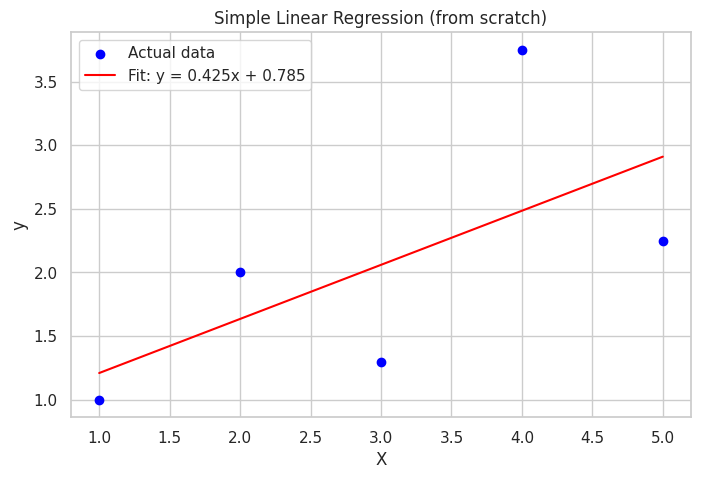

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 2, 1.3, 3.75, 2.25])

class SimpleLinearRegression:
    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X, y):
        # X shape: (n, 1) → flatten to (n,)
        x = X.flatten()
        x_mean = x.mean()
        y_mean = y.mean()

        # Closed-form solution
        numerator = np.sum((x - x_mean) * (y - y_mean))
        denominator = np.sum((x - x_mean) ** 2)
        self.w = numerator / denominator
        self.b = y_mean - self.w * x_mean
        return self

    def predict(self, X):
        x = X.flatten()
        return self.w * x + self.b

# Fit
slr = SimpleLinearRegression()
slr.fit(X, y)
print(f"Slope (w): {slr.w:.4f}, Intercept (b): {slr.b:.4f}")

# Predict
y_pred = slr.predict(X)
print("Predictions:", np.round(y_pred, 4))
print("Actual:     ", y)

# Visualize
plt.figure(figsize=(8, 5))
plt.scatter(X.flatten(), y, color='blue', label='Actual data', zorder=3)
plt.plot(X.flatten(), y_pred, color='red', label=f'Fit: y = {slr.w:.3f}x + {slr.b:.3f}')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Simple Linear Regression (from scratch)')
plt.legend()
plt.grid(True)
plt.show()

Coefficients [bias, x1, x2]: [ 2.0625 -2.375   3.25  ]
Predictions: [2.9375 6.1875 3.8125 5.3125]
Actual:      [3.25 6.5  3.5  5.  ]


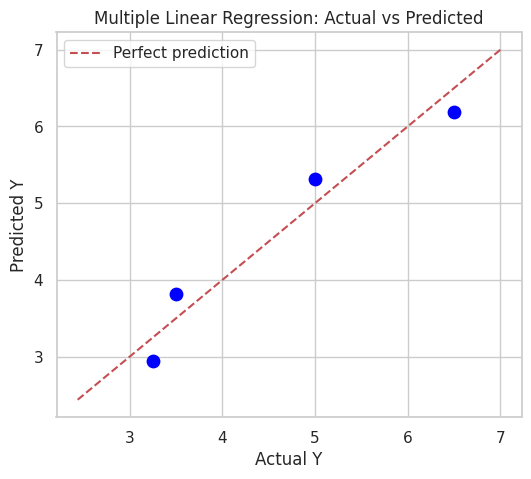

Residuals: [ 0.3125  0.3125 -0.3125 -0.3125]
R²: 0.9425


In [5]:
X_m = np.array([
    [1, 1, 1],
    [1, 1, 2],
    [1, 2, 2],
    [1, 0, 1]
])
Y = np.array([3.25, 6.5, 3.5, 5.0])

class MultipleLinearRegression:
    def __init__(self):
        self.coef_ = None

    def fit(self, X, y):
        # Normal equation: w = (X^T X)^-1 X^T y
        # Using lstsq for numerical stability (avoids explicit inverse)
        self.coef_, *_ = np.linalg.lstsq(X, y, rcond=None)
        return self

    def predict(self, X):
        return X @ self.coef_

# Fit
mlr = MultipleLinearRegression()
mlr.fit(X_m, Y)
print("Coefficients [bias, x1, x2]:", np.round(mlr.coef_, 4))

# Predict
y_pred_m = mlr.predict(X_m)
print("Predictions:", np.round(y_pred_m, 4))
print("Actual:     ", Y)

# Visualize: actual vs predicted
plt.figure(figsize=(6, 5))
plt.scatter(Y, y_pred_m, color='blue', s=80, zorder=3)
lims = [min(Y.min(), y_pred_m.min()) - 0.5, max(Y.max(), y_pred_m.max()) + 0.5]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual Y')
plt.ylabel('Predicted Y')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()

# Residuals
residuals = Y - y_pred_m
print("Residuals:", np.round(residuals, 6))
print(f"R²: {1 - np.sum(residuals**2) / np.sum((Y - Y.mean())**2):.4f}")

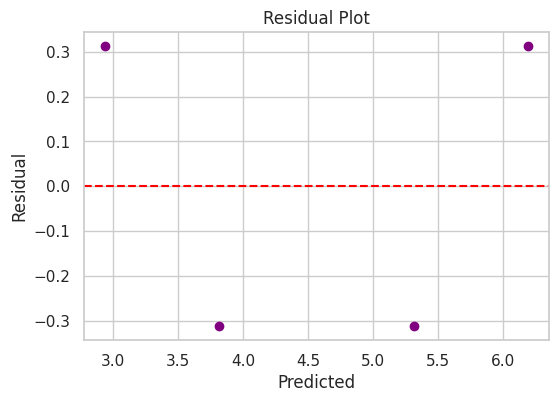

In [6]:
plt.figure(figsize=(6, 4))
plt.scatter(y_pred_m, residuals, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.grid(True)
plt.show()

Optimized result: 1.976941569907863


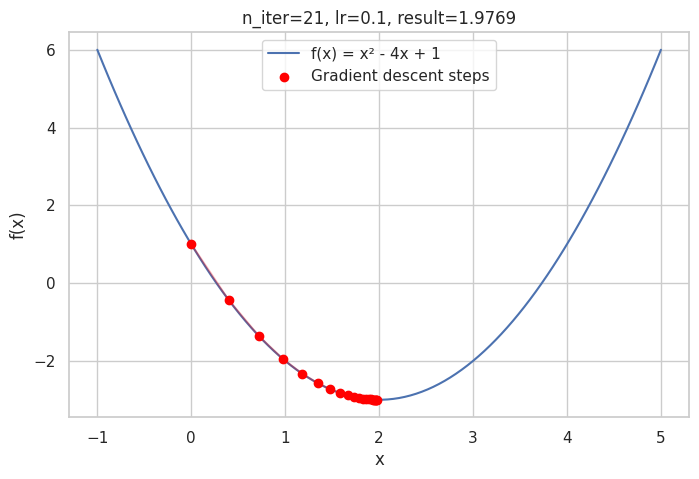

In [7]:
def func(x):
    return x**2 - 4*x + 1

def grad_func(x):
    return 2*x - 4

def gradient_descent(starting_point, gradient_func, learning_rate,
                     max_iter=100, tolerance=1e-6):
    x = starting_point
    history = [x]
    for i in range(max_iter):
        grad = gradient_func(x)
        if abs(grad) < tolerance:
            break
        x = x - learning_rate * grad
        history.append(x)
    return history, x

# Run
lr = 0.1
history, result = gradient_descent(
    starting_point=0.0,
    gradient_func=grad_func,
    learning_rate=lr,
    max_iter=20,
    tolerance=1e-6
)
print("Optimized result:", result)

# Plot
history_array = np.array(history)
x_vals = np.linspace(-1, 5, 100)
y_vals = func(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label='f(x) = x² - 4x + 1')
plt.scatter(history_array, func(history_array), color='red', label='Gradient descent steps', zorder=3)
plt.plot(history_array, func(history_array), color='red', alpha=0.3)
plt.legend()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title(f'n_iter={len(history)}, lr={lr}, result={result:.4f}')
plt.show()

In [8]:
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    !pip install ucimlrepo
    from ucimlrepo import fetch_ucirepo

auto_mpg = fetch_ucirepo(id=9)
X = auto_mpg.data.features
y = auto_mpg.data.targets

print(X.shape, y.shape)  # (398, 7) (398, 1)
print(auto_mpg.metadata['name'])  # Auto MPG

(398, 7) (398, 1)
Auto MPG


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Recombine and clean (as done in EDA)
df = pd.concat([X, y], axis=1)
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Separate
X_clean = df.drop(columns='mpg')
y_clean = df['mpg']

# Define column groups
num_cols = ['displacement', 'horsepower', 'weight', 'acceleration']
ordinal_cols = ['cylinders', 'model_year']   # keep as numeric (ordinal)
nominal_cols = ['origin']                     # one-hot encode

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols + ordinal_cols),
        ('cat', OneHotEncoder(drop='first'), nominal_cols),
    ]
)

In [10]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

# Pipeline: preprocess → model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression()),
])

# Fit
model.fit(X_train, y_train)
print("Model trained!")

Model trained!


In [11]:
# Predict
y_pred = model.predict(X_test)

# Metrics
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f"MAE : {mae:.4f}  (avg error in MPG)")
print(f"MSE : {mse:.4f}")
print(f"RMSE: {rmse:.4f}  (same units as MPG)")
print(f"R²  : {r2:.4f}")

MAE : 2.2882  (avg error in MPG)
MSE : 8.3387
RMSE: 2.8877  (same units as MPG)
R²  : 0.8449


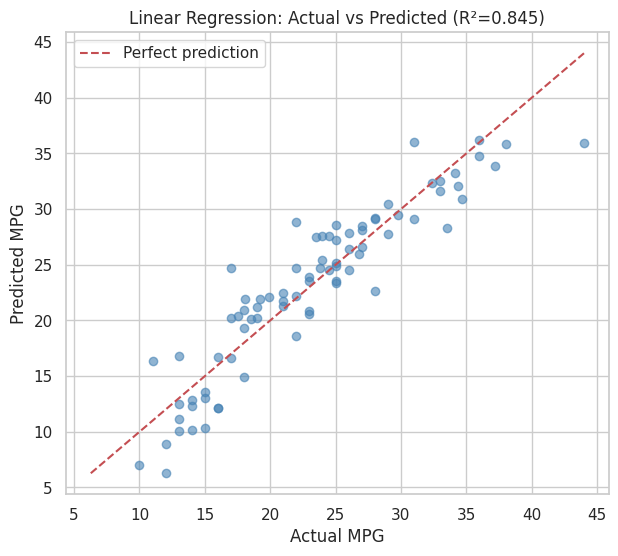

In [12]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual MPG')
plt.ylabel('Predicted MPG')
plt.title(f'Linear Regression: Actual vs Predicted (R²={r2:.3f})')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Extract feature names after preprocessing
feature_names = (
    num_cols + ordinal_cols
    + list(model.named_steps['preprocessor']
                .named_transformers_['cat']
                .get_feature_names_out(nominal_cols))
)
coefs = model.named_steps['regressor'].coef_

coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index)
print(coef_df)

        Feature  Coefficient
2        weight    -5.914735
5    model_year     2.971431
6      origin_2     2.946907
7      origin_3     2.671126
0  displacement     2.033373
1    horsepower    -0.539182
4     cylinders    -0.278695
3  acceleration     0.187514


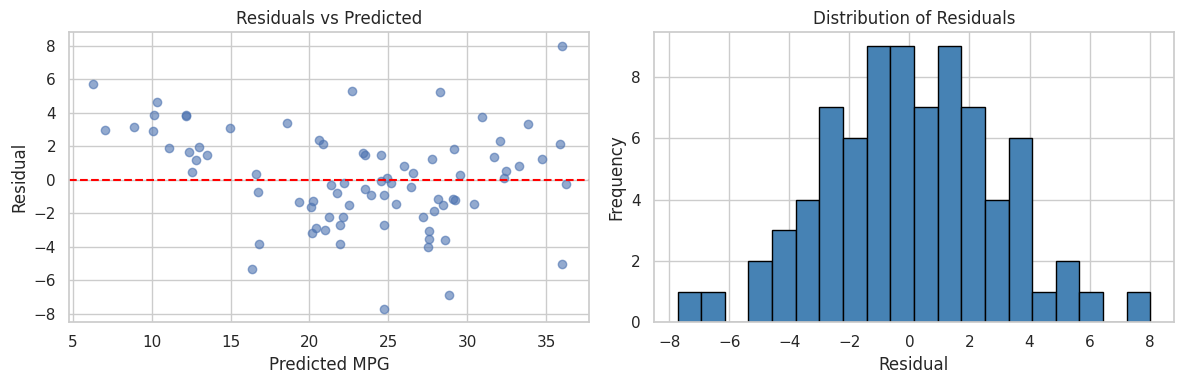

In [14]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Residuals vs predicted
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted MPG')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predicted')

# Histogram of residuals
axes[1].hist(residuals, bins=20, color='steelblue', edgecolor='black')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.show()